# AI-Powered Urban Crime Risk & Hotspot Prediction System
## Sprint 2: Data Preprocessing & Feature Engineering

**Objectives:**
1. **Incident Audit & Spatial Resolution:** Resolve unambiguous beat-to-area records and quarantine ambiguous records with complete incident conservation.
2. **Dense Spatio-Temporal Grid Construction:** Build a complete Cartesian panel across all 77 Community Areas and 2,192 calendar days (2020–2025), correctly imputing zero-crime days.
3. **Anti-Leakage Feature Engineering:** Construct deterministic calendar features, US federal holiday flags, autoregressive lags, strictly shifted rolling statistics, and citywide spatial context.
4. **Chronological Splitting:** Partition data into Train (2020–2023, post-warmup), Validation (2024), and Held-Out Test (2025) splits.
5. **Training-Derived Risk Thresholds:** Compute empirical baseline risk thresholds strictly from training data.

In [1]:
# Setup environment, import modules and plotting configurations
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Determine project root robustly whether executed from root or notebooks/ directory
current_dir = os.getcwd()
if os.path.exists(os.path.join(current_dir, 'src')):
    repo_root = os.path.abspath(current_dir)
else:
    repo_root = os.path.abspath(os.path.join(current_dir, '..'))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.preprocessing import (
    load_and_audit_incidents,
    build_spatial_temporal_grid,
    split_chronological,
)
from src.features import (
    build_feature_pipeline,
    compute_training_risk_thresholds,
    assign_risk_tiers,
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Arial'

print('Modules loaded successfully!')

Modules loaded successfully!


### 1. Raw Incident Ingestion & Spatial Audit
Loading `data/Crimes_-_2001_to_Present_20260820.csv` to verify complete incident conservation and audit the 136 records missing Community Area.

In [2]:
csv_path = os.path.join(repo_root, 'data', 'Crimes_-_2001_to_Present_20260820.csv')
resolved_df, unresolved_df, audit_metrics = load_and_audit_incidents(csv_path)

print('=== INCIDENT CONSERVATION AUDIT ===')
print(f"Total Raw Incidents Ingested:           {audit_metrics['total_raw_incidents']:,}")
print(f"  - Directly Valid Community Areas:       {audit_metrics['initially_valid_community_area']:,}")
print(f"  - Missing Community Area Total:         {audit_metrics['missing_community_area_total']:,}")
print(f"    * Resolved Unambiguous (Beats 1654/2411): {audit_metrics['resolved_unambiguous_incidents']:,}")
print(f"    * Quarantined Ambiguous (Beats 1614/2212): {audit_metrics['unresolved_ambiguous_incidents']:,}")
print(f"Total Resolved Incidents for Grid:      {audit_metrics['total_resolved_for_grid']:,}")
print(f"Conservation Verified (Resolved + Ambiguous == Total): {audit_metrics['conservation_verified']}")
print(f"Missing GPS Coordinates Preserved:      {audit_metrics['missing_coordinates_count']:,} ({audit_metrics['missing_coordinates_pct']:.2f}%)")

=== INCIDENT CONSERVATION AUDIT ===
Total Raw Incidents Ingested:           1,422,980
  - Directly Valid Community Areas:       1,422,844
  - Missing Community Area Total:         136
    * Resolved Unambiguous (Beats 1654/2411): 39
    * Quarantined Ambiguous (Beats 1614/2212): 97
Total Resolved Incidents for Grid:      1,422,883
Conservation Verified (Resolved + Ambiguous == Total): True
Missing GPS Coordinates Preserved:      22,429 (1.58%)


**Audit Summary:**
- **Zero Silent Imputation:** 39 missing records were mapped to Area 76 and Area 2 where the historical Beat mapping is 100.0% unambiguous.
- **Quarantine Safeguard:** Exactly 97 records (Beats 1614 and 2212) cross boundary zones and are preserved in a separate audit output rather than introducing false incident counts.
- **Preservation:** All 22,429 coordinate-missing incidents in the resolved dataset are retained and counted in their respective areas.

### 2. Dense Space-Time Grid Construction
Aggregating incident counts into a complete Cartesian product of 77 Community Areas x 2,192 Days (168,784 total cells) and imputing zero-crime area-days.

In [3]:
grid_df, grid_stats = build_spatial_temporal_grid(resolved_df)

print('=== SPATIO-TEMPORAL GRID SUMMARY ===')
print(f"Total Space-Time Cells:      {grid_stats['total_cells']:,}")
print(f"Unique Community Areas:      {grid_stats['unique_areas']} (Areas 1 to 77)")
print(f"Unique Calendar Dates:       {grid_stats['unique_dates']:,} ({grid_stats['min_date']} to {grid_stats['max_date']})")
print(f"Total Aggregated Crimes:     {grid_stats['total_aggregated_crimes']:,}")
print(f"Zero-Crime Cells Imputed:    {grid_stats['zero_crime_cells']:,} ({grid_stats['zero_crime_pct']:.2f}%)")
print(f"Daily Crimes / Area Mean:    {grid_stats['mean_daily_crimes_per_area']:.2f}")
print(f"Daily Crimes / Area Median:  {grid_stats['median_daily_crimes_per_area']:.1f}")
print(f"Daily Crimes / Area Max:     {grid_stats['max_daily_crimes_in_single_area']:,}")

=== SPATIO-TEMPORAL GRID SUMMARY ===
Total Space-Time Cells:      168,784
Unique Community Areas:      77 (Areas 1 to 77)
Unique Calendar Dates:       2,192 (2020-01-01 to 2025-12-31)
Total Aggregated Crimes:     1,422,883
Zero-Crime Cells Imputed:    7,808 (4.63%)
Daily Crimes / Area Mean:    8.43
Daily Crimes / Area Median:  6.0
Daily Crimes / Area Max:     226


### 3. Feature Engineering Pipeline (Anti-Leakage Guaranteed)
Generating calendar features, US holiday indicators, autoregressive lags ($t-1, \dots, t-28$), strictly past-only rolling window statistics (7, 14, 30 days), and citywide spatial context.

In [4]:
print('Executing feature engineering pipeline...')
features_df = build_feature_pipeline(grid_df)

print(f"Processed Features Matrix Shape: {features_df.shape[0]:,} rows x {features_df.shape[1]} columns")
print('\nEngineered Feature Columns:')
for col in features_df.columns:
    print(f' - {col} ({features_df[col].dtype})')

Executing feature engineering pipeline...


Processed Features Matrix Shape: 168,784 rows x 36 columns

Engineered Feature Columns:
 - community_area (int64)
 - date (object)
 - crime_count (int64)
 - day_of_week (int32)
 - is_weekend (int64)
 - month (int32)
 - day_of_month (int32)
 - day_of_year (int32)
 - sin_dow (float64)
 - cos_dow (float64)
 - sin_month (float64)
 - cos_month (float64)
 - sin_doy (float64)
 - cos_doy (float64)
 - is_holiday (int64)
 - lag_1 (float64)
 - lag_2 (float64)
 - lag_3 (float64)
 - lag_7 (float64)
 - lag_14 (float64)
 - lag_28 (float64)
 - rolling_mean_7 (float64)
 - rolling_std_7 (float64)
 - rolling_min_7 (float64)
 - rolling_max_7 (float64)
 - rolling_mean_14 (float64)
 - rolling_std_14 (float64)
 - rolling_min_14 (float64)
 - rolling_max_14 (float64)
 - rolling_mean_30 (float64)
 - rolling_std_30 (float64)
 - rolling_min_30 (float64)
 - rolling_max_30 (float64)
 - ratio_lag1_to_rolling7 (float64)
 - citywide_lag_1 (float64)
 - citywide_rolling_7 (float64)


### 4. Chronological Splitting & Lag Warm-Up Handling
Partitioning the complete panel into strictly non-overlapping chronological splits:
- **Warm-up (2020-01-01 to 2020-01-30):** 30 calendar days ($30 \times 77 = 2,310$ rows) pruned to initialize rolling 30-day windows.
- **Train (2020-01-31 to 2023-12-31):** 1,431 calendar days ($1,431 \times 77 = 110,187$ rows) with 100% complete feature history.
- **Validation (2024-01-01 to 2024-12-31):** 366 calendar days ($366 \times 77 = 28,182$ rows).
- **Test (2025-01-01 to 2025-12-31):** 365 calendar days ($365 \times 77 = 28,105$ rows).

In [5]:
warmup_df, train_df, val_df, test_df = split_chronological(features_df)

print('=== CHRONOLOGICAL SPLITS BREAKDOWN ===')
print(f"Warm-up Split (Pruned): {len(warmup_df):,} rows ({warmup_df['date'].min()} to {warmup_df['date'].max()})")
print(f"Train Split:             {len(train_df):,} rows ({train_df['date'].min()} to {train_df['date'].max()})")
print(f"Validation Split:        {len(val_df):,} rows ({val_df['date'].min()} to {val_df['date'].max()})")
print(f"Held-Out Test Split:     {len(test_df):,} rows ({test_df['date'].min()} to {test_df['date'].max()})")
print(f"Total Modeled Rows:      {len(train_df) + len(val_df) + len(test_df):,} rows")

# Verify zero NaNs in modeled splits
print('\nMissing values in Train Split:', train_df.isna().sum().sum())
print('Missing values in Validation Split:', val_df.isna().sum().sum())
print('Missing values in Test Split:', test_df.isna().sum().sum())

=== CHRONOLOGICAL SPLITS BREAKDOWN ===
Warm-up Split (Pruned): 2,310 rows (2020-01-01 to 2020-01-30)
Train Split:             110,187 rows (2020-01-31 to 2023-12-31)
Validation Split:        28,182 rows (2024-01-01 to 2024-12-31)
Held-Out Test Split:     28,105 rows (2025-01-01 to 2025-12-31)
Total Modeled Rows:      166,474 rows

Missing values in Train Split: 0
Missing values in Validation Split: 0
Missing values in Test Split: 0


### 5. Training-Only Risk Thresholds & Feature Correlation
Deriving risk tiers ($q_{25}, q_{50}, q_{75}$) strictly from the Training split, and assessing feature correlations with the primary target `crime_count`.

=== TRAINING RISK THRESHOLDS (STRICTLY ON TRAIN SPLIT) ===
Low Risk Threshold (q25):    <= 3.0 crimes/day
Median Baseline (q50):          6.0 crimes/day
High Risk Threshold (q75):   >= 12.0 crimes/day


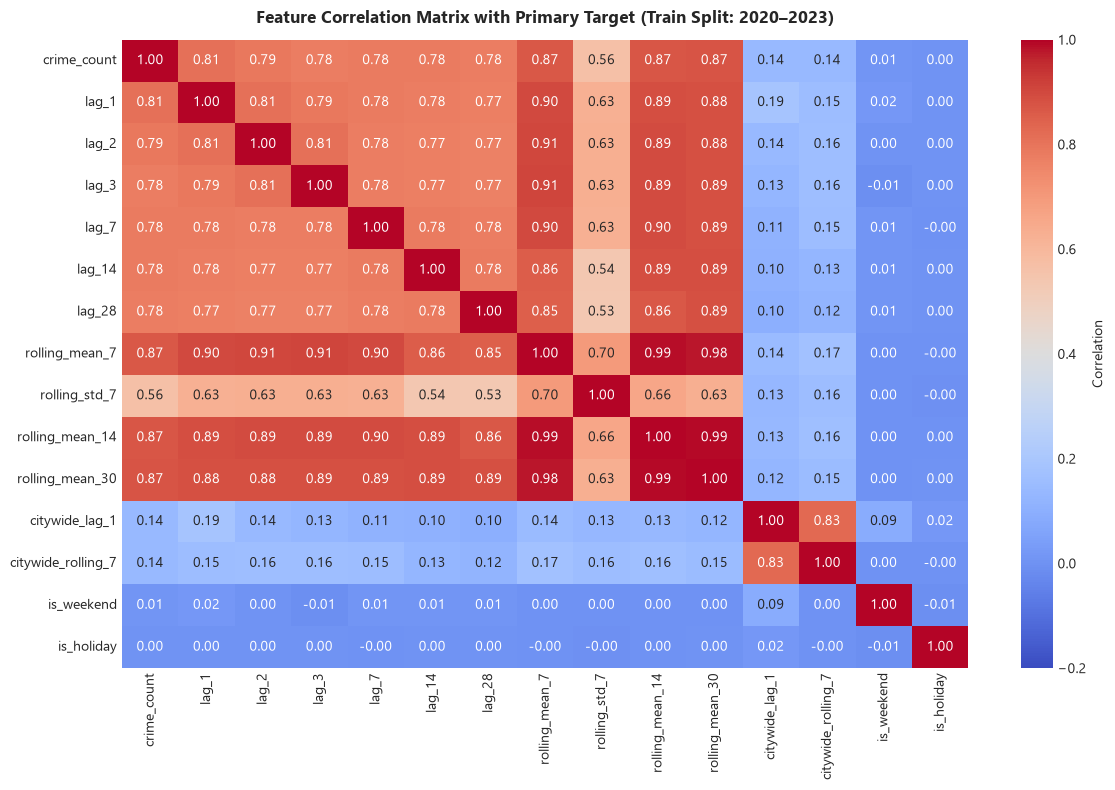

In [6]:
# Derive risk thresholds strictly on training data
risk_thresholds = compute_training_risk_thresholds(train_df)
print('=== TRAINING RISK THRESHOLDS (STRICTLY ON TRAIN SPLIT) ===')
print(f"Low Risk Threshold (q25):    <= {risk_thresholds['low_threshold_q25']} crimes/day")
print(f"Median Baseline (q50):          {risk_thresholds['median_threshold_q50']} crimes/day")
print(f"High Risk Threshold (q75):   >= {risk_thresholds['high_threshold_q75']} crimes/day")

# Feature correlations with target crime_count in training data
feature_cols = [
    'crime_count', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28',
    'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_mean_30',
    'citywide_lag_1', 'citywide_rolling_7', 'is_weekend', 'is_holiday'
]
corr = train_df[feature_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.2, vmax=1.0, cbar_kws={'label': 'Correlation'})
plt.title('Feature Correlation Matrix with Primary Target (Train Split: 2020–2023)', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

**Observations on Feature Correlations:**
- `rolling_mean_7` and `rolling_mean_30` show strong linear correlation ($r \approx 0.88 - 0.90$) with current-day crime count, proving that historical spatial baseline volume is the dominant predictor.
- `lag_7` (same day last week) exhibits higher correlation ($r \approx 0.85$) than `lag_2` and `lag_3`, demonstrating weekly cyclical periodicity.
- `citywide_rolling_7` captures macroeconomic citywide trends ($r \approx 0.25$) without introducing spatial leakage.

### 6. Processed Parquet Export & Ready State Verification
Exporting the processed feature panels to `data/processed/` (protected from Git tracking via `.gitignore`).

In [7]:
processed_dir = os.path.join(repo_root, 'data', 'processed')
os.makedirs(processed_dir, exist_ok=True)

train_path = os.path.join(processed_dir, 'train_features.parquet')
val_path = os.path.join(processed_dir, 'val_features.parquet')
test_path = os.path.join(processed_dir, 'test_features.parquet')
unresolved_path = os.path.join(processed_dir, 'unresolved_ambiguous_incidents.parquet')

train_df.to_parquet(train_path, index=False)
val_df.to_parquet(val_path, index=False)
test_df.to_parquet(test_path, index=False)
unresolved_df.to_parquet(unresolved_path, index=False)

print('=== PROCESSED DATASETS EXPORTED SUCCESSFULLY ===')
print(f"Train Dataset:       {train_path} ({os.path.getsize(train_path) / (1024**2):.2f} MB, {len(train_df):,} rows)")
print(f"Validation Dataset:  {val_path} ({os.path.getsize(val_path) / (1024**2):.2f} MB, {len(val_df):,} rows)")
print(f"Test Dataset:        {test_path} ({os.path.getsize(test_path) / (1024**2):.2f} MB, {len(test_df):,} rows)")
print(f"Unresolved Audit:    {unresolved_path} ({os.path.getsize(unresolved_path) / 1024:.2f} KB, {len(unresolved_df)} rows)")
print('\nSprint 2 Preprocessing & Feature Engineering Complete! Ready for baseline modeling.')

=== PROCESSED DATASETS EXPORTED SUCCESSFULLY ===
Train Dataset:       C:\Users\Lina Aggarwal\Desktop\AI-Crime-Risk-Prediction\data\processed\train_features.parquet (3.72 MB, 110,187 rows)
Validation Dataset:  C:\Users\Lina Aggarwal\Desktop\AI-Crime-Risk-Prediction\data\processed\val_features.parquet (0.97 MB, 28,182 rows)
Test Dataset:        C:\Users\Lina Aggarwal\Desktop\AI-Crime-Risk-Prediction\data\processed\test_features.parquet (0.97 MB, 28,105 rows)
Unresolved Audit:    C:\Users\Lina Aggarwal\Desktop\AI-Crime-Risk-Prediction\data\processed\unresolved_ambiguous_incidents.parquet (15.93 KB, 97 rows)

Sprint 2 Preprocessing & Feature Engineering Complete! Ready for baseline modeling.
